In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
# Load data
df = pd.read_csv("del-sirifort-cpcb-2024-25 (1).csv")

# Select columns
cols = ['PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO2 (µg/m³)', 'Ozone (µg/m³)']
data = df[cols].apply(pd.to_numeric, errors='coerce').fillna(0)

In [3]:
# 1. Preprocessing
print(data.head())
print("Shape:", data.shape)
print("Missing values:\n", data.isnull().sum())

   PM2.5 (µg/m³)  PM10 (µg/m³)  NO2 (µg/m³)  Ozone (µg/m³)
0         199.10         290.0        81.70            6.4
1         199.10         290.0        80.97            6.5
2         199.10         290.0        78.59            6.0
3         206.04         294.0        77.94            5.7
4         227.20         305.0        77.82            5.8
Shape: (70177, 4)
Missing values:
 PM2.5 (µg/m³)    0
PM10 (µg/m³)     0
NO2 (µg/m³)      0
Ozone (µg/m³)    0
dtype: int64


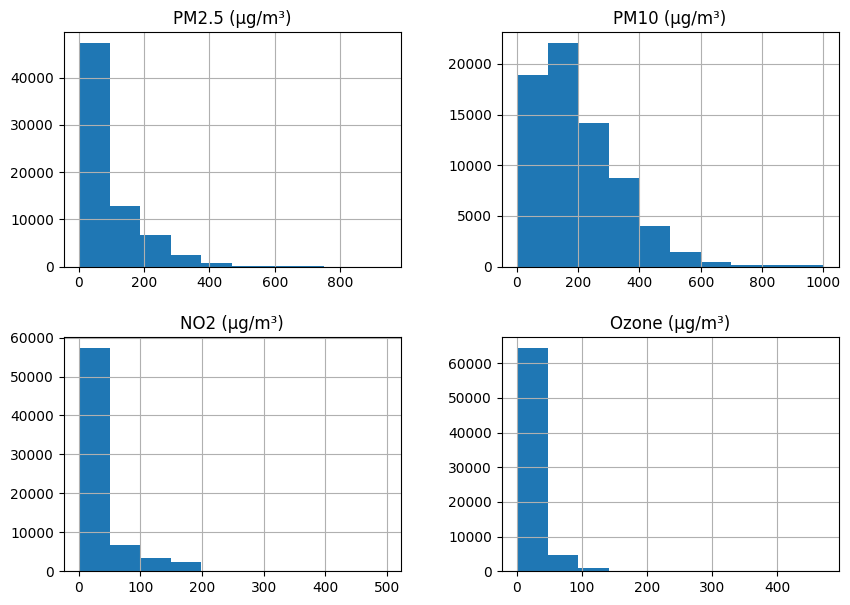

In [4]:
# 2. Distribution - Histogram
data.hist(figsize=(10,7))
plt.show()

In [5]:
# 3. Numerical Summary
print("\nNumerical Summary:")
print(data.describe().T[['mean', 'min', '25%', '50%', '75%', 'max']])
print("\nMode:")
print(data.mode().iloc[0])


Numerical Summary:
                     mean  min    25%     50%     75%      max
PM2.5 (µg/m³)   87.565467  0.0  24.00   52.33  128.00   938.40
PM10 (µg/m³)   199.571669  0.0  93.89  169.60  278.00  1000.00
NO2 (µg/m³)     45.529495  0.0  31.29   36.94   45.14   497.45
Ozone (µg/m³)   25.768960  0.0  15.06   22.02   30.06   470.39

Mode:
PM2.5 (µg/m³)    0.0
PM10 (µg/m³)     0.0
NO2 (µg/m³)      0.0
Ozone (µg/m³)    0.0
Name: 0, dtype: float64


In [6]:
# 4. Measures of Spread
print("\nMeasures of Spread:")
print("Range:\n", data.max() - data.min())
print("Variance:\n", data.var())
print("Standard Deviation:\n", data.std())
print("CV (%):\n", (data.std()/data.mean())*100)


Measures of Spread:
Range:
 PM2.5 (µg/m³)     938.40
PM10 (µg/m³)     1000.00
NO2 (µg/m³)       497.45
Ozone (µg/m³)     470.39
dtype: float64
Variance:
 PM2.5 (µg/m³)     9099.392953
PM10 (µg/m³)     20371.622283
NO2 (µg/m³)       1320.042993
Ozone (µg/m³)      418.173274
dtype: float64
Standard Deviation:
 PM2.5 (µg/m³)     95.390738
PM10 (µg/m³)     142.729192
NO2 (µg/m³)       36.332396
Ozone (µg/m³)     20.449285
dtype: float64
CV (%):
 PM2.5 (µg/m³)    108.936481
PM10 (µg/m³)      71.517762
NO2 (µg/m³)       79.799691
Ozone (µg/m³)     79.356269
dtype: float64


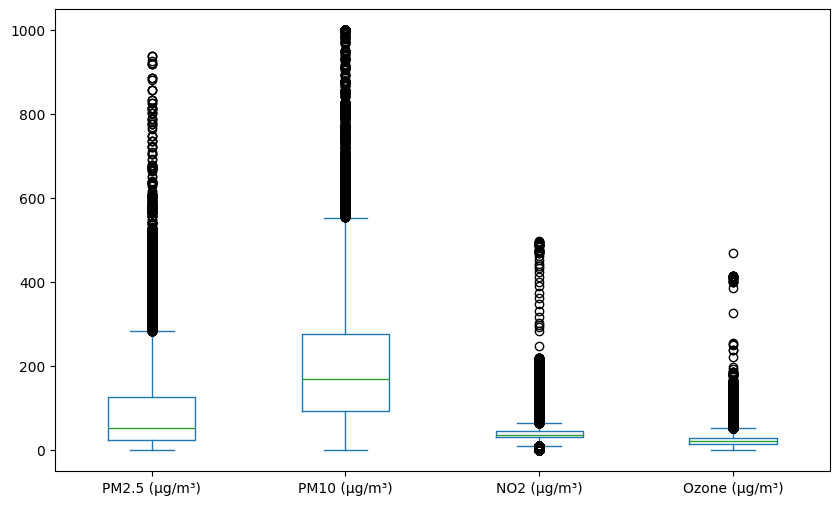

PM2.5 (µg/m³) Outliers: 3316
PM10 (µg/m³) Outliers: 1382
NO2 (µg/m³) Outliers: 12665
Ozone (µg/m³) Outliers: 4665


In [7]:
# 5. Boxplot + Outliers
data.plot(kind='box', figsize=(10,6))
plt.show()

for c in cols:
    Q1 = data[c].quantile(.25)
    Q3 = data[c].quantile(.75)
    IQR = Q3 - Q1
    out = data[(data[c] < Q1-1.5*IQR) | (data[c] > Q3+1.5*IQR)]
    print(c, "Outliers:", len(out))

In [8]:
# 6. Min-Max Scaling
mm = MinMaxScaler()
print("\nMin-Max Scaling:")
print(pd.DataFrame(mm.fit_transform(data), columns=cols).head())


Min-Max Scaling:
   PM2.5 (µg/m³)  PM10 (µg/m³)  NO2 (µg/m³)  Ozone (µg/m³)
0       0.212170         0.290     0.164238       0.013606
1       0.212170         0.290     0.162770       0.013818
2       0.212170         0.290     0.157986       0.012755
3       0.219565         0.294     0.156679       0.012118
4       0.242114         0.305     0.156438       0.012330


In [9]:
# 7. Z-Score Standardization
ss = StandardScaler()
print("\nZ-Score:")
print(pd.DataFrame(ss.fit_transform(data), columns=cols).head())


Z-Score:
   PM2.5 (µg/m³)  PM10 (µg/m³)  NO2 (µg/m³)  Ozone (µg/m³)
0       1.169247      0.633570     0.995551      -0.947177
1       1.169247      0.633570     0.975459      -0.942287
2       1.169247      0.633570     0.909952      -0.966738
3       1.242001      0.661596     0.892062      -0.981409
4       1.463827      0.738665     0.888759      -0.976518


In [10]:
# 8. Gini Coefficient

def gini(x):
    x = np.sort(x)
    n = len(x)
    return (2 * np.sum((np.arange(1, n+1)) * x)) / (n * np.sum(x)) - (n+1)/n

print("\nGini Coefficient:")

for c in cols:
    print(c, ":", round(gini(data[c].values), 4))


Gini Coefficient:
PM2.5 (µg/m³) : 0.5484
PM10 (µg/m³) : 0.3837
NO2 (µg/m³) : 0.3396
Ozone (µg/m³) : 0.3554
